In [1]:
# Keep imports and data/output paths relative to the repository root.
import os
import sys
from pathlib import Path
from datetime import datetime
from uuid import uuid4

for repository_dir in (Path.cwd(), *Path.cwd().parents):
    if (repository_dir / ".geofm-root").is_file():
        os.chdir(repository_dir)
        break
else:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if "src" not in sys.path:
    sys.path.insert(0, "src")

EXPERIMENT_NAME = "sen1floods11/terramind/fcn_s1"
NOTEBOOK_PATH = "experiments/sen1floods11/terramind/fcn_s1/02_terramind_on_sen1floods11_test.ipynb"


In [2]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import math
import json
import pandas as pd

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from IPython.display import display


In [3]:
# One-time setup in this notebook kernel: %pip install terratorch==1.2.5 torchgeo==0.8.1
# TerraMind input reference: https://github.com/IBM/terramind/blob/main/configs/terramind_v1_base_sen1floods11.yaml
import hashlib
from importlib.metadata import version
from segmentation_metrics import binary_metrics, metric_table, save_json, save_per_chip_metrics

CROP_SIZE = 120
IGNORE_INDEX = 255
SEED = 42
SCHEMA = "terramind_large_s1_fcn_v1"
PREPROCESSING = {
    "name": "terramind_v1_s1grd", "bands": ["VV", "VH"],
    "mean": [-12.599, -20.293], "std": [5.195, 5.890],
    "nonfinite_raw_replacement": 0.0, "clip": None,
    "patch_size": 16, "padding": "right_bottom_replicate_to_multiple_of_16",
    "crop_size": CROP_SIZE, "ignore_index": IGNORE_INDEX,
}
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
crop_generator = torch.Generator().manual_seed(SEED)
loader_generator = torch.Generator().manual_seed(SEED)


def sha256_file(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


def load_split_paths(csv_file, x_dir, y_dir):
    with open(csv_file, newline="") as handle:
        pairs = [(Path(x_dir) / x.strip(), Path(y_dir) / y.strip()) for x, y in csv.reader(handle)]
    missing = [str(p) for pair in pairs for p in pair if not p.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing split inputs or labels: {missing[:5]}")
    return pairs


def audit_splits(index_dir, x_dir, y_dir):
    result, seen = {}, set()
    for split, filename, count in [
        ("train", "flood_train_data.csv", 252), ("valid", "flood_valid_data.csv", 89),
        ("non_bol", "flood_test_data.csv", 90), ("bol", "flood_bolivia_data.csv", 15),
    ]:
        path = Path(index_dir) / filename
        pairs = load_split_paths(path, x_dir, y_dir)
        ids = [y.name.removesuffix("_LabelHand.tif") for x, y in pairs]
        if len(ids) != count or len(set(ids)) != count or seen.intersection(ids):
            raise ValueError(f"Unexpected count, duplicate or split overlap: {split}")
        seen.update(ids)
        result[split] = {"count": count, "csv_sha256": sha256_file(path), "chip_ids": ids}
    return result


def load_image_pair(pair):
    with rasterio.open(pair[0]) as image_src, rasterio.open(pair[1]) as label_src:
        if (image_src.shape != label_src.shape or image_src.crs != label_src.crs
                or not image_src.transform.almost_equals(label_src.transform)):
            raise ValueError(f"Image/label grid mismatch: {pair}")
        image = image_src.read().astype(np.float32)
        mask = label_src.read(1).astype(np.int64)
    # Raw Sen1Floods11 S1 is already VV/VH in dB; no CROMA clipping or scaling.
    image = np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)
    return image, mask


def prepare_sample(data):
    image, mask = data
    image = torch.as_tensor(image, dtype=torch.float32)
    mask = torch.as_tensor(mask, dtype=torch.long).clone()
    mask[mask == -1] = IGNORE_INDEX
    if image.ndim != 3 or image.shape[0] != 2 or mask.shape != image.shape[-2:]:
        raise ValueError("Expected aligned VV/VH image and two-dimensional mask")
    if not set(torch.unique(mask).tolist()).issubset({0, 1, IGNORE_INDEX}):
        raise ValueError("Unexpected target values")
    mean = image.new_tensor(PREPROCESSING["mean"])[:, None, None]
    std = image.new_tensor(PREPROCESSING["std"])[:, None, None]
    image = (image - mean) / std
    if not torch.isfinite(image).all():
        raise ValueError("Nonfinite normalized input")
    return image, mask


class Sen1Floods11Dataset(Dataset):
    def __init__(self, data_list, preprocess_func):
        self.data_list = data_list
        self.preprocess_func = preprocess_func

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, index):
        return self.preprocess_func(load_image_pair(self.data_list[index]))


def load_terramind(pretrained_path):
    # Check compatibility before TerraTorch imports its optional model factories.
    from importlib.metadata import PackageNotFoundError
    required = {"terratorch": "1.2.5", "torchgeo": "0.8.1"}
    installed = {}
    for package in required:
        try:
            installed[package] = version(package)
        except PackageNotFoundError:
            installed[package] = "not installed"
    if installed != required:
        raise RuntimeError(
            f"Incompatible notebook environment: {installed}. "
            "Run %pip install terratorch==1.2.5 torchgeo==0.8.1, "
            "restart the kernel, then Run All."
        )
    try:
        from terratorch.models.backbones.terramind.model.terramind_register import terramind_v1_large
    except ImportError as exc:
        raise ImportError(
            f"TerraTorch import failed with {installed}: {exc}. "
            "Inspect the underlying dependency error; restart the kernel after package changes."
        ) from exc
    # Keep the checkpoint's 224-grid positional embeddings; TerraMind interpolates them at forward time.
    backbone = terramind_v1_large(pretrained=False, modalities=["S1GRD"], img_size=224,
                                 merge_method="mean")
    state = torch.load(pretrained_path, map_location="cpu", weights_only=True, mmap=True)
    expected = backbone.state_dict()
    missing = [k for k in expected if k not in state]
    mismatched = [k for k in expected if k in state and expected[k].shape != state[k].shape]
    if missing or mismatched:
        raise RuntimeError(f"Incomplete backbone weights: missing={missing[:5]}, shape mismatch={mismatched[:5]}")
    # Ignore only unused modalities and the generative decoder; every selected encoder tensor must load.
    backbone.load_state_dict({k: state[k] for k in expected}, strict=True)
    backbone.requires_grad_(False).eval()
    print(f"Loaded all {len(expected)} S1 encoder tensors from the local checkpoint.")
    return backbone


class TerraMindFloodSegmentation(nn.Module):
    def __init__(self, terramind, head, encoder_batch_size=4):
        super().__init__()
        self.terramind = terramind.requires_grad_(False).eval()
        self.head = head
        self.encoder_batch_size = encoder_batch_size

    def train(self, mode=True):
        super().train(mode)
        self.terramind.eval()
        return self

    def forward(self, images):
        height, width = images.shape[-2:]
        ph, pw = (-height) % 16, (-width) % 16
        padded = F.pad(images, (0, pw, 0, ph), mode="replicate")
        gh, gw = padded.shape[-2] // 16, padded.shape[-1] // 16
        # Chunk only the frozen encoder to fit memory; keep the effective head batch unchanged.
        with torch.no_grad():
            features = [self.terramind({"S1GRD": chunk})[-1]
                        for chunk in padded.split(self.encoder_batch_size)]
            tokens = torch.cat(features, dim=0)
        if tokens.shape[1:] != (gh * gw, 1024):
            raise ValueError(f"Unexpected final TerraMind token shape: {tuple(tokens.shape)}")
        maps = tokens.transpose(1, 2).reshape(images.shape[0], 1024, gh, gw)
        logits = self.head(maps)
        logits = F.interpolate(logits, size=padded.shape[-2:], mode="bilinear", align_corners=False)
        return logits[..., :height, :width]


#### **First things first**


In [4]:
model_name = "terramind_large_s1_fcn.pt"
# Optional explicit selection; None discovers the most recent completed compatible run.
CHECKPOINT_PATH = None


In [5]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/terramind/TerraMind_v1_large.pt"

path_to_the_dataset = "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "datasets/sen1floods11/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S1Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_permanent_water = path_to_the_dataset + "JRCWaterHand"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)
split_manifest = audit_splits(path_to_the_dataset_index, path_to_X, path_to_Y)
print({k: v["count"] for k, v in split_manifest.items()})


cuda
{'train': 252, 'valid': 89, 'non_bol': 90, 'bol': 15}


#### **Functions**

In [6]:
def preprocess_test(data):
    return prepare_sample(data)


#### **Creating datasets**

In [7]:
test_data_non_bolivia = load_split_paths(path_to_test_csv, path_to_X, path_to_Y)
test_data_bolivia = load_split_paths(path_to_test_bolivia_csv, path_to_X, path_to_Y)

In [8]:
print(f"Non bolivia test samples: {len(test_data_non_bolivia)}")
print(f"Bolivia test samples: {len(test_data_bolivia)}")

Non bolivia test samples: 90
Bolivia test samples: 15


In [9]:
print(test_data_non_bolivia[0])
print(test_data_bolivia[0])

(WindowsPath('datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Ghana_313799_S1Hand.tif'), WindowsPath('datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_313799_LabelHand.tif'))
(WindowsPath('datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif'), WindowsPath('datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif'))


In [10]:
test_dataset_non_bolivia = Sen1Floods11Dataset(
 data_list = test_data_non_bolivia,
 preprocess_func=preprocess_test
)

test_dataset_bolivia = Sen1Floods11Dataset(
 data_list = test_data_bolivia,
 preprocess_func=preprocess_test
)

In [11]:
test_loader_non_bolivia = DataLoader(
    test_dataset_non_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_bolivia = DataLoader(
    test_dataset_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

#### **Model**

In [12]:
terramind = load_terramind(pretrained_path).to(device)


d:\UNI\THESIS\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
W1103 11:13:12.700000 27828 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loaded all 221 S1 encoder tensors from the local checkpoint.


In [13]:
terramind.requires_grad_(False) # Freeze the weights of TerraMind
terramind.eval()

TerraMindViT(
  (encoder_embeddings): ModuleDict(
    (untok_sen1grd@224): ImageEncoderEmbedding(
      (proj): Linear(in_features=512, out_features=1024, bias=False)
    )
  )
  (encoder): ModuleList(
    (0-23): 24 x Block(
      (norm1): LayerNorm()
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=False)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=False)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm()
      (mlp): GatedMlp(
        (fc1): Linear(in_features=1024, out_features=2730, bias=False)
        (act): SiLU()
        (fc2): Linear(in_features=2730, out_features=1024, bias=False)
        (fc3): Linear(in_features=1024, out_features=2730, bias=False)
      )
    )
  )
  (encoder_norm): LayerNorm()
  (tokenizer): ModuleDict()
)

#### **Creating the head**

In [14]:
head = FCNHead(in_channels=1024, channels=2)

head[1] = nn.GroupNorm(
    num_groups=16,
    num_channels=256
)

head = head.to(device)

In [15]:
experiment_dir = Path("runs") / EXPERIMENT_NAME
candidates = []
for manifest_path in experiment_dir.glob("train_*/run.json"):
    metadata = json.loads(manifest_path.read_text(encoding="utf-8"))
    history_file = Path(metadata.get("history", ""))
    candidate = Path(metadata.get("checkpoint", ""))
    if metadata.get("schema") != SCHEMA or not history_file.is_file() or not candidate.is_file():
        continue
    history_record = json.loads(history_file.read_text(encoding="utf-8"))
    if history_record.get("epochs_completed") != metadata.get("epochs"):
        continue
    candidates.append((metadata["started_at"], candidate))
if CHECKPOINT_PATH is None:
    if not candidates:
        raise FileNotFoundError("No completed TerraMind training run. Run the training notebook first.")
    checkpoint_path = max(candidates, key=lambda item: item[0])[1]
else:
    checkpoint_path = Path(CHECKPOINT_PATH)
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
training_config = checkpoint["run_config"]
if training_config["schema"] != SCHEMA or training_config["preprocessing"] != PREPROCESSING:
    raise ValueError("Checkpoint architecture/preprocessing does not match this notebook")
if training_config["splits"] != split_manifest:
    raise ValueError("Dataset split membership or CSV content changed since training")
if training_config["pretrained_sha256"] != sha256_file(pretrained_path):
    raise ValueError("Pretrained TerraMind weights differ from the training run")
head.load_state_dict(checkpoint["head_state_dict"], strict=True)
print(f"Loading checkpoint: {checkpoint_path}; selected epoch: {checkpoint['epoch']}")


Loading checkpoint: runs\sen1floods11\terramind\fcn_s1\train_terramind_large_s1_fcn_2026-11-02_23-18-59_066004_c59ba713\terramind_large_s1_fcn.pt; selected epoch: 71


In [16]:
model = TerraMindFloodSegmentation(terramind, head).to(device)
model.eval()

TerraMindFloodSegmentation(
  (terramind): TerraMindViT(
    (encoder_embeddings): ModuleDict(
      (untok_sen1grd@224): ImageEncoderEmbedding(
        (proj): Linear(in_features=512, out_features=1024, bias=False)
      )
    )
    (encoder): ModuleList(
      (0-23): 24 x Block(
        (norm1): LayerNorm()
        (attn): Attention(
          (qkv): Linear(in_features=1024, out_features=3072, bias=False)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=1024, out_features=1024, bias=False)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (drop_path): Identity()
        (norm2): LayerNorm()
        (mlp): GatedMlp(
          (fc1): Linear(in_features=1024, out_features=2730, bias=False)
          (act): SiLU()
          (fc2): Linear(in_features=2730, out_features=1024, bias=False)
          (fc3): Linear(in_features=1024, out_features=2730, bias=False)
        )
      )
    )
    (encoder_norm): LayerNorm()
    (tokenize

In [17]:
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor([1.0, 8.0], device=device),
    ignore_index=IGNORE_INDEX
)

In [18]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=60,
    tile_batch_size=8
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen TerraMind + trained FCN head.

    image:
        Tensor [2, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each TerraMind input (120).

    stride:
        Distance between consecutive windows (60 = 50% overlap).

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 2
    assert H >= tile_size and W >= tile_size
    assert 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        starts = list(
            range(0, length - tile_size + 1, stride)
        )

        # Ensure the final window reaches the image boundary
        if starts[-1] != length - tile_size:
            starts.append(length - tile_size)

        return starts

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen TerraMind + FCN head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)

@torch.inference_mode()
def test(
    model,
    valid_loader,
    criterion,
    device,
    save_predictions=False,
    save_dir=None,
    test_data=None,
    save_metrics=True
):
    model.eval()

    if criterion.reduction != "mean":
        raise ValueError("This implementation expects reduction='mean'.")

    save_dir = run_results_dir / "test" if save_dir is None else Path(save_dir)

    if save_predictions:
        if test_data is None:
            raise ValueError("Provide test_data to save georeferenced predictions.")

        if not hasattr(valid_loader.dataset, "data_list"):
            raise ValueError("Expected a dataset with data_list.")

        if list(test_data) != list(valid_loader.dataset.data_list):
            raise ValueError("test_data must match the dataset order.")

        if valid_loader.batch_size != 1:
            raise ValueError("Use batch_size=1 to save predictions.")

        if not isinstance(
            valid_loader.sampler,
            torch.utils.data.SequentialSampler
        ):
            raise ValueError("Use shuffle=False when saving predictions.")

    if save_predictions or save_metrics:
        save_dir.mkdir(parents=True, exist_ok=True)

    total_loss = 0.0
    total_weight = 0.0

    TP = FP = FN = TN = 0
    sample_idx = 0
    chip_rows = []

    for images, masks in valid_loader:

        for image, mask in zip(images, masks):

            mask = mask.cpu().long()
            valid = mask != IGNORE_INDEX
            n_valid = valid.sum().item()

            # Full-image sliding-window inference
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=CROP_SIZE // 2,
                tile_batch_size=8
            )

            prediction = logits.argmax(dim=0)

            # Save georeferenced prediction
            if save_predictions:

                x_path, y_path = test_data[sample_idx]
                x_path = Path(x_path)

                output_path = (
                    save_dir / f"{x_path.stem}_prediction.tif"
                )

                with rasterio.open(x_path) as src:
                    profile = src.profile.copy()

                profile.update(
                    driver="GTiff",
                    count=1,
                    dtype="uint8",
                    nodata=None
                )

                pred_np = prediction.numpy().astype(np.uint8)

                with rasterio.open(output_path, "w", **profile) as dst:
                    dst.write(pred_np, 1)

            chip_counts = (
                int(((prediction == 1) & (mask == 1) & valid).sum()),
                int(((prediction == 1) & (mask == 0) & valid).sum()),
                int(((prediction == 0) & (mask == 1) & valid).sum()),
                int(((prediction == 0) & (mask == 0) & valid).sum()),
            )
            chip_id = Path(valid_loader.dataset.data_list[sample_idx][0]).stem.removesuffix("_S1Hand")
            chip_rows.append({"chip_id": chip_id, "region": chip_id.split("_")[0],
                              **binary_metrics(*chip_counts)})
            sample_idx += 1

            # Ignore samples without any valid ground-truth pixels
            if n_valid == 0:
                continue

            # Compute loss on the criterion's device
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device)

            loss = criterion(logits_device, mask_device)

            # Correct aggregation for weighted/unweighted CE
            if criterion.weight is not None:
                image_weight = criterion.weight[
                    mask_device[mask_device != IGNORE_INDEX]
                ].sum().item()
            else:
                image_weight = n_valid

            total_loss += loss.item() * image_weight
            total_weight += image_weight

            # Confusion matrix for the water class
            TP += (
                (prediction == 1) & (mask == 1) & valid
            ).sum().item()

            FP += (
                (prediction == 1) & (mask == 0) & valid
            ).sum().item()

            FN += (
                (prediction == 0) & (mask == 1) & valid
            ).sum().item()

            TN += (
                (prediction == 0) & (mask == 0) & valid
            ).sum().item()

    if total_weight == 0:
        raise RuntimeError("No valid test pixels.")

    def safe_div(numerator, denominator):
        return (
            numerator / denominator
            if denominator > 0
            else float("nan")
        )

    # Segmentation metrics (global / pooled)
    water_iou = safe_div(TP, TP + FP + FN)
    nonwater_iou = safe_div(TN, TN + FP + FN)
    miou = (water_iou + nonwater_iou) / 2

    # Classification metrics for water
    precision = safe_div(TP, TP + FP)
    recall = safe_div(TP, TP + FN)
    f1 = safe_div(2 * TP, 2 * TP + FP + FN)

    # Remote sensing error rates
    omission = safe_div(FN, TP + FN)
    commission = safe_div(FP, TP + FP)

    accuracy = safe_div(TP + TN, TP + TN + FP + FN)

    metrics = {
        "test_loss": total_loss / total_weight,
        "water_iou": water_iou,
        "nonwater_iou": nonwater_iou,
        "miou": miou,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "omission_error": omission,
        "commission_error": commission,
        "accuracy": accuracy,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
    }

    metrics.update(binary_metrics(TP, FP, FN, TN))

    if save_metrics:
        save_per_chip_metrics(chip_rows, save_dir)
        # Use null for undefined metrics in standards-compliant JSON
        json_metrics = {
            k: (
                None
                if isinstance(v, float) and not math.isfinite(v)
                else v
            )
            for k, v in metrics.items()
        }

        with open(save_dir / "metrics.json", "w") as f:
            json.dump(json_metrics, f, indent=4)

    return metrics

In [19]:
# A new directory is created each time this run cell is executed.
run_id = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S_%f") + "_" + uuid4().hex[:8]
run_results_dir = Path("runs") / EXPERIMENT_NAME / f"test_{checkpoint_path.stem}_{run_id}"
run_results_dir.mkdir(parents=True, exist_ok=False)
print(f"Run directory: {run_results_dir}")

with (run_results_dir / "run.json").open("w", encoding="utf-8") as run_file:
    json.dump({
        "experiment": EXPERIMENT_NAME,
        "schema": SCHEMA, "training_config": training_config,
        "checkpoint_epoch": checkpoint["epoch"], "checkpoint_sha256": sha256_file(checkpoint_path),
        "model_name": checkpoint_path.stem,
        "phase": "test",
        "run_id": run_id,
        "started_at": datetime.now().astimezone().isoformat(),
        "notebook": NOTEBOOK_PATH,
        "pretrained_weights": pretrained_path,
    "checkpoint": checkpoint_path.as_posix(),
    }, run_file, indent=4)

metrics_nonbolivia = test(
    model=model,
    valid_loader=test_loader_non_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir=run_results_dir / "non_bol",
    test_data=test_data_non_bolivia
)

print("Non Bolivia test: ",metrics_nonbolivia)

Run directory: runs\sen1floods11\terramind\fcn_s1\test_terramind_large_s1_fcn_2026-11-03_11-13-38_529912_5c5295f9


2026-11-03 11:13:39,491 - WARNING - CPLE_IllegalArg in Ghana_313799_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:39,979 - WARNING - CPLE_IllegalArg in Ghana_1078550_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:40,330 - WARNING - CPLE_IllegalArg in Ghana_97059_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:40,679 - WARNING - CPLE_IllegalArg in Ghana_359826_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:41,049 - WARNING - CPLE_IllegalArg in Ghana_319168_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:41,416 - WARNING - CPLE_IllegalArg in Ghana_866994_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:41,770 - WARNING - CPLE_IllegalArg in Ghana_406026_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:13:42,130 - WARNING - CPLE_IllegalArg in Ghana_5

Non Bolivia test:  {'test_loss': 0.3379615000520195, 'water_iou': 0.6526485963760235, 'nonwater_iou': 0.9413851294593839, 'miou': 0.7970168629177037, 'precision': 0.7864565966540618, 'recall': 0.793215076101837, 'f1': 0.7898213786126954, 'omission_error': 0.206784923898163, 'commission_error': 0.21354340334593822, 'accuracy': 0.9472001451258342, 'TP': 2035470, 'FP': 552683, 'FN': 530631, 'TN': 17398583, 'specificity': 0.9692120321764492, 'false_positive_rate': 0.030787967823550717, 'balanced_accuracy': 0.881213554139143, 'mcc': 0.7596388101402944, 'ground_truth_water_fraction': 0.1250697031446579, 'predicted_water_fraction': 0.12614449992535592, 'valid_pixels': 20517367}


In [20]:
metrics_bolivia = test(
    model=model,
    valid_loader=test_loader_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir=run_results_dir / "bol",
    test_data=test_data_bolivia
)

print("Bolivia test: ", metrics_bolivia)
metric_table({"non_bol": metrics_nonbolivia, "bol": metrics_bolivia}, run_results_dir)


2026-11-03 11:14:13,132 - WARNING - CPLE_IllegalArg in Bolivia_103757_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:13,476 - WARNING - CPLE_IllegalArg in Bolivia_129334_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:13,801 - WARNING - CPLE_IllegalArg in Bolivia_195474_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:14,178 - WARNING - CPLE_IllegalArg in Bolivia_23014_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:14,535 - WARNING - CPLE_IllegalArg in Bolivia_233925_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:14,886 - WARNING - CPLE_IllegalArg in Bolivia_242570_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:15,228 - WARNING - CPLE_IllegalArg in Bolivia_290290_S1Hand_prediction.tif: BLOCKXSIZE can only be used with TILED=YES
2026-11-03 11:14:15,569 - WARNING - CPLE_IllegalA

Bolivia test:  {'test_loss': 0.3362052245053183, 'water_iou': 0.6178591420018565, 'nonwater_iou': 0.9125037713033863, 'miou': 0.7651814566526214, 'precision': 0.7469919273312694, 'recall': 0.7813786098702029, 'f1': 0.7637984370349438, 'omission_error': 0.21862139012979703, 'commission_error': 0.25300807266873054, 'accuracy': 0.9233475660040833, 'TP': 355421, 'FP': 120382, 'FN': 99443, 'TN': 2292569, 'specificity': 0.950110051965415, 'false_positive_rate': 0.04988994803458504, 'balanced_accuracy': 0.865744330917809, 'mcc': 0.7183355638673998, 'ground_truth_water_fraction': 0.1586099521761341, 'predicted_water_fraction': 0.16591132970571673, 'valid_pixels': 2867815}


,test_loss,water_iou,nonwater_iou,miou,precision,recall,f1,omission_error,commission_error,accuracy,...,FP,FN,TN,specificity,false_positive_rate,balanced_accuracy,mcc,ground_truth_water_fraction,predicted_water_fraction,valid_pixels
split,,,,,,,,,,,,,,,,,,,,,
non_bol,0.337962,0.652649,0.941385,0.797017,0.786457,0.793215,0.789821,0.206785,0.213543,0.947200,...,552683,530631,17398583,0.969212,0.030788,0.881214,0.759639,0.12507,0.126144,20517367
bol,0.336205,0.617859,0.912504,0.765181,0.746992,0.781379,0.763798,0.218621,0.253008,0.923348,...,120382,99443,2292569,0.950110,0.049890,0.865744,0.718336,0.15861,0.165911,2867815


In [21]:
def aw_pw_fw_targets(
    path_to_labels,
    path_to_predictions,
    path_to_permanent_water,
):
    labels_dir = Path(path_to_labels)
    predictions_dir = Path(path_to_predictions)
    permanent_dir = Path(path_to_permanent_water)

    suffix = "_S1Hand_prediction.tif"
    prediction_files = sorted(predictions_dir.glob(f"*{suffix}"))

    if not prediction_files:
        raise FileNotFoundError(
            f"No prediction files found in {predictions_dir}"
        )

    for prediction_path in prediction_files:
        chip_id = prediction_path.name.removesuffix(suffix)

        label_path = labels_dir / f"{chip_id}_LabelHand.tif"
        permanent_path = permanent_dir / f"{chip_id}_JRCWaterHand.tif"

        for path in (label_path, permanent_path):
            if not path.is_file():
                raise FileNotFoundError(path)

        with (
            rasterio.open(prediction_path) as pred_src,
            rasterio.open(label_path) as label_src,
            rasterio.open(permanent_path) as perm_src,
        ):
            # Allow tiny floating-point differences in georeferencing.
            for src in (pred_src, perm_src):
                if (
                    src.shape != label_src.shape
                    or src.crs != label_src.crs
                    or not src.transform.almost_equals(
                        label_src.transform, precision=1e-10
                    )
                ):
                    raise ValueError(f"Raster grid mismatch: {chip_id}")

            prediction = pred_src.read(1)
            y = label_src.read(1).astype(np.int16)
            p = perm_src.read(1)

        y[y == -1] = 255

        if not np.isin(prediction, [0, 1]).all():
            raise ValueError(f"Non-binary prediction: {chip_id}")
        if not np.isin(y, [0, 1, 255]).all():
            raise ValueError(f"Unexpected hand labels: {chip_id}")
        if not np.isin(p, [0, 1]).all():
            raise ValueError(f"Unexpected JRC values: {chip_id}")

        targets = {
            "AW": y.copy(),
            "PW": y.copy(),
            "FW": y.copy(),
        }

        targets["PW"][(y == 1) & (p == 0)] = 255
        targets["FW"][(y == 1) & (p == 1)] = 255

        # Historical rule: exclude chips whose water positives
        # disappear after category masking. Retain originally dry chips.
        originally_has_water = np.any(y == 1)
        included = {
            category: not (
                category != "AW"
                and originally_has_water
                and not np.any(target == 1)
            )
            for category, target in targets.items()
        }

        yield {
            "chip_id": chip_id,
            "prediction": prediction,
            "targets": targets,
            "included": included,
        }

In [22]:
hand_dir = Path(
    "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled"
)

rows = []

for split in ("non_bol", "bol"):
    records = aw_pw_fw_targets(
        path_to_labels=hand_dir / "LabelHand",
        path_to_predictions=run_results_dir / split,
        path_to_permanent_water=hand_dir / "JRCWaterHand",
    )

    for record in records:
        prediction = record["prediction"]

        for category, target in record["targets"].items():
            if not record["included"][category]:
                continue

            valid = target != 255

            tp = np.count_nonzero(valid & (prediction == 1) & (target == 1))
            fp = np.count_nonzero(valid & (prediction == 1) & (target == 0))
            fn = np.count_nonzero(valid & (prediction == 0) & (target == 1))
            tn = np.count_nonzero(valid & (prediction == 0) & (target == 0))

            rows.append({
                "split": split,
                "category": category,
                "chip_id": record["chip_id"],
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "chip_iou": (tp + 1e-7) / (tp + fp + fn + 1e-7),
            })

per_chip = pd.DataFrame(rows)

summary = (
    per_chip.groupby(["split", "category"], sort=False)
    .agg(
        evaluated_chips=("chip_id", "size"),
        mean_chip_iou=("chip_iou", "mean"),
        tp=("tp", "sum"),
        fp=("fp", "sum"),
        fn=("fn", "sum"),
        tn=("tn", "sum"),
    )
    .reset_index()
)

union = summary["tp"] + summary["fp"] + summary["fn"]
summary["total_iou"] = summary["tp"] / union.replace(0, np.nan)

display(summary[
    ["split", "category", "evaluated_chips", "mean_chip_iou", "total_iou"]
])

per_chip.to_csv(run_results_dir / "terramind_aw_pw_fw_per_chip.csv", index=False)
summary.to_csv(run_results_dir / "terramind_aw_pw_fw_summary.csv", index=False)

,split,category,evaluated_chips,mean_chip_iou,total_iou
0,non_bol,AW,90,0.397618,0.652649
1,non_bol,FW,90,0.318157,0.513151
2,non_bol,PW,54,0.421242,0.679151
3,bol,AW,15,0.413246,0.617859
4,bol,FW,15,0.344383,0.599433
5,bol,PW,7,0.328153,0.301666


In [23]:
from IPython.display import display, Markdown

for split, title in [
    ("non_bol", "Table 1. Non-Bolivia test set"),
    ("bol", "Table 2. Bolivia test set"),
]:
    scores = (
        summary.loc[summary["split"].eq(split)]
        .set_index("category")["mean_chip_iou"]
        .reindex(["PW", "FW", "AW"])
    )

    table = pd.DataFrame(
        [scores.to_numpy()],
        columns=["PW", "FW", "AW"],
        index=["TerraMind + FCN head"],
    )
    table.index.name = "Model"

    display(Markdown(f"**{title} — Mean per-chip water IoU**"))
    display(table.style.format("{:.4f}"))

**Table 1. Non-Bolivia test set — Mean per-chip water IoU**

,PW,FW,AW
Model,,,
TerraMind + FCN head,0.4212,0.3182,0.3976


**Table 2. Bolivia test set — Mean per-chip water IoU**

,PW,FW,AW
Model,,,
TerraMind + FCN head,0.3282,0.3444,0.4132


In [24]:
from sen1floods11_visualization import plot_predictions as _plot_predictions

def plot_predictions(**kwargs):
    save_path = kwargs.pop("save_path", None)
    fig, axes, chip_ids = _plot_predictions(**kwargs)
    for row in axes:
        row[2].set_title(row[2].get_title().replace("CROMA", "TerraMind"))
    if save_path is not None:
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    return fig, axes, chip_ids


fig, axes, chip_ids = plot_predictions(
    predictions_dir=run_results_dir / "non_bol",
    hand_dir="datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled",
    n=90,
    seed=42,
    save_path=run_results_dir / "terramind_visualization_90.png",
    show_errors=True
)

plt.show()

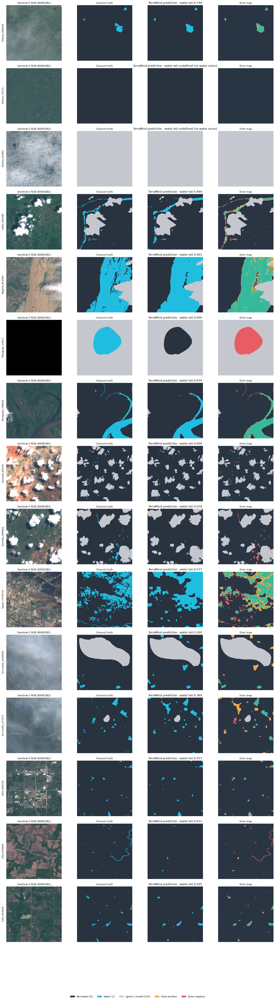

In [25]:

fig, axes, chip_ids = plot_predictions(
    predictions_dir=run_results_dir / "non_bol",
    hand_dir="datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled",
    n=15,
    seed=42,
    save_path=run_results_dir / "terramind_visualization_15.png",
    show_errors=True
)

plt.show()

In [26]:
m = metrics_nonbolivia

tp, fp, fn, tn = (
    m["TP"], m["FP"], m["FN"], m["TN"]
)

total = tp + fp + fn + tn

print(f"Ground-truth water: {(tp + fn) / total:.2%}")
print(f"Predicted water:    {(tp + fp) / total:.2%}")
print(f"Precision:          {m['precision']:.4f}")
print(f"Recall:             {m['recall']:.4f}")
print(f"Water IoU:          {m['water_iou']:.4f}")
# Keep a compact comparison with the existing S1 FCN evaluation; retain source provenance.
croma_root = Path("runs/sen1floods11/croma/fcn_s1")
croma_tests = sorted(p for p in croma_root.glob("test_*")
                     if (p / "non_bol/metrics.json").is_file() and (p / "bol/metrics.json").is_file())
comparison_rows = []
for split, current in [("non_bol", metrics_nonbolivia), ("bol", metrics_bolivia)]:
    sources = [("TerraMind Large + FCN", current, run_results_dir)]
    if croma_tests:
        reference_dir = croma_tests[-1]
        sources.append(("CROMA Large + FCN (existing run)",
                        json.loads((reference_dir / split / "metrics.json").read_text()), reference_dir))
    for label, scores, source in sources:
        valid_pixels = sum(scores[k] for k in ["TP", "FP", "FN", "TN"])
        same_valid_count = valid_pixels == current["valid_pixels"]
        comparison_rows.append({"split": split, "model": label, "source_run": source.as_posix(),
            "valid_pixels": valid_pixels, "same_valid_pixel_count": same_valid_count,
            **{k: scores[k] for k in ["miou", "water_iou", "precision", "recall", "f1", "accuracy"]}})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(run_results_dir / "croma_terramind_s1_comparison.csv", index=False)
save_json(run_results_dir / "croma_terramind_s1_comparison.json", comparison_rows)
display(comparison)
# Equal valid-pixel counts are a consistency check, not proof of identical training protocols.


Ground-truth water: 12.51%
Predicted water:    12.61%
Precision:          0.7865
Recall:             0.7932
Water IoU:          0.6526


,split,model,source_run,valid_pixels,same_valid_pixel_count,miou,water_iou,precision,recall,f1,accuracy
0,non_bol,TerraMind Large + FCN,runs/sen1floods11/terramind/fcn_s1/test_terram...,20517367,True,0.797017,0.652649,0.786457,0.793215,0.789821,0.947200
1,non_bol,CROMA Large + FCN (existing run),runs/sen1floods11/croma/fcn_s1/test_croma_best...,20517367,True,0.793508,0.647826,0.768960,0.804397,0.786280,0.945308
2,bol,TerraMind Large + FCN,runs/sen1floods11/terramind/fcn_s1/test_terram...,2867815,True,0.765181,0.617859,0.746992,0.781379,0.763798,0.923348
3,bol,CROMA Large + FCN (existing run),runs/sen1floods11/croma/fcn_s1/test_croma_best...,2867815,True,0.744961,0.600288,0.645025,0.896428,0.750225,0.905325
